<a href="https://colab.research.google.com/github/Apurba213/Ostad_AI-Ml-engineering-course/blob/main/Module14_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Dog vs Cat Image Classification

Introduction

The objective of this project is to build a deep learning system that classifies images into two categories: cats and dogs.

The project explores dataset preparation, data augmentation, convolutional neural networks (CNNs), transfer learning, full fine-tuning, model evaluation,
nd error analysis.

Technologies:Python, TensorFlow, Keras, NumPy, Matplotlib, and Scikit-learn.

Dataset:Dog vs Cat image dataset.

Evaluation:Accuracy, precision, recall, F1-score, loss curves, confusion matrix, and classification report.

In [ ]:
#import libraries
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score)

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

In [ ]:
# Download the dataset from GitHub
!git clone https://github.com/laxmimerit/dog-cat-full-dataset.git

Cloning into 'dog-cat-full-dataset'...
remote: Enumerating objects: 25059, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 25059 (delta 4), reused 6 (delta 2), pack-reused 25048 (from 1)
Receiving objects: 100% (25059/25059), 541.54 MiB | 18.66 MiB/s, done.
Resolving deltas: 100% (21/21), done.
Updating files: 100% (24990/24990), done.


In [ ]:
# Define the dataset directory
DATA_DIR = "/content/dog-cat-full-dataset/data"

# Define the training and testing directories
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")

# Check whether the directories exist
print("Training directory exists:", os.path.exists(TRAIN_DIR))
print("Testing directory exists:", os.path.exists(TEST_DIR))

# Display the class folders
print("Training folders:", os.listdir(TRAIN_DIR))
print("Testing folders:", os.listdir(TEST_DIR))

Training directory exists: True
Testing directory exists: True
Training folders: ['cats', 'dogs']
Testing folders: ['cats', 'dogs']


Question 1: Dataset Preparation, followed by this Code cell.

In [ ]:
#1.1
DATA_DIR  = "dog-cat-full-dataset/data"
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR  = os.path.join(DATA_DIR, "test")

IMG_SIZE   = (224, 224)   # all images resized to 224 x 224 while loading
BATCH_SIZE = 32
AUTOTUNE   = tf.data.AUTOTUNE

# 80% training / 20% validation split of the training directory
train_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary")

val_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary")

# Test set: no shuffling so predictions line up with labels
test_raw = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="binary", shuffle=False)

class_names = train_raw.class_names
print("\nClass names:", class_names, "-> label 0 =", class_names[0], ", label 1 =", class_names[1])
print("Training samples  :", len(train_raw.file_paths))
print("Validation samples:", len(val_raw.file_paths))
print("Test samples      :", len(test_raw.file_paths))

Found 19989 files belonging to 2 classes.
Using 15992 files for training.
Found 19989 files belonging to 2 classes.
Using 3997 files for validation.
Found 5000 files belonging to 2 classes.

Class names: ['cats', 'dogs'] -> label 0 = cats , label 1 = dogs
Training samples  : 15992
Validation samples: 3997
Test samples      : 5000


In [ ]:
#1.2
# Normalize pixel values from [0, 255] to [0, 1] and prefetch for efficient training
normalization = layers.Rescaling(1.0 / 255)

def prepare(ds):
    ds = ds.map(lambda x, y: (normalization(x), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(buffer_size=AUTOTUNE)

train_ds = prepare(train_raw)
val_ds   = prepare(val_raw)
test_ds  = prepare(test_raw)

# Sanity check: pixel range and shapes
images, labels = next(iter(train_ds))
print("Batch shape:", images.shape, "| labels shape:", labels.shape)
print("Pixel range: min = %.3f, max = %.3f" % (images.numpy().min(), images.numpy().max()))

Batch shape: (32, 224, 224, 3) | labels shape: (32, 1)
Pixel range: min = 0.000, max = 1.000


Question 2: Data Augmentation

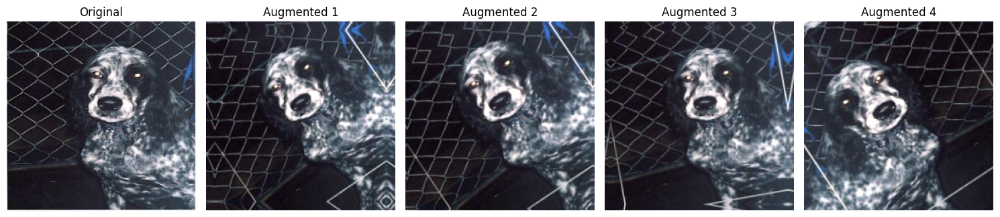

In [ ]:
#2.1
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.2),      # additional augmentation of our choice
], name="data_augmentation")

# Show one original image and four augmented versions
sample = images[0]
plt.figure(figsize=(15, 3.5))
plt.subplot(1, 5, 1)
plt.imshow(sample.numpy()); plt.title("Original"); plt.axis("off")
for i in range(4):
    aug = data_augmentation(tf.expand_dims(sample, 0), training=True)[0]
    plt.subplot(1, 5, i + 2)
    plt.imshow(np.clip(aug.numpy(), 0, 1)); plt.title(f"Augmented {i+1}"); plt.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
#2.2
def plot_history(history, title):
    """Plot training vs validation accuracy and loss."""
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, h["accuracy"], "o-", label="Train accuracy")
    plt.plot(epochs, h["val_accuracy"], "o-", label="Validation accuracy")
    plt.title(f"{title}: Accuracy"); plt.xlabel("Epoch"); plt.ylabel("Accuracy")
    plt.legend(); plt.grid(alpha=0.3); plt.show()

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, h["loss"], "o-", label="Train loss")
    plt.plot(epochs, h["val_loss"], "o-", label="Validation loss")
    plt.title(f"{title}: Loss"); plt.xlabel("Epoch"); plt.ylabel("Binary cross-entropy")
    plt.legend(); plt.grid(alpha=0.3); plt.show()

Question 3: Custom CNN Model

In [ ]:
#3.1
def conv_block(x, filters, dropout_rate):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Dropout(dropout_rate)(x)
    return x

def build_custom_cnn():
    inputs = layers.Input(shape=(*IMG_SIZE, 3))
    x = data_augmentation(inputs)                       # active only in training
    for filters, drop in [(32, 0.1), (64, 0.2), (128, 0.3), (256, 0.3)]:
        x = conv_block(x, filters, drop)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)  # P(class 1 = dog)
    return models.Model(inputs, outputs, name="custom_cnn")

custom_cnn = build_custom_cnn()
custom_cnn.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             

 Total params: 422,881 (1.61 MB)

 Trainable params: 421,921 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
#3.2: Compile and train Custom CNN

custom_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_cnn = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping]
)

Epoch 1/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 91s 166ms/step - accuracy: 0.5879 - loss: 0.6665 - val_accuracy: 0.6215 - val_loss: 0.6350
Epoch 2/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 163ms/step - accuracy: 0.6471 - loss: 0.6273 - val_accuracy: 0.6155 - val_loss: 0.6503
Epoch 3/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 81s 163ms/step - accuracy: 0.6824 - loss: 0.5945 - val_accuracy: 0.5767 - val_loss: 0.7280
Epoch 4/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 81s 162ms/step - accuracy: 0.7014 - loss: 0.5747 - val_accuracy: 0.6965 - val_loss: 0.5780
Epoch 5/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 81s 162ms/step - accuracy: 0.7095 - loss: 0.5679 - val_accuracy: 0.6540 - val_loss: 0.6014
Epoch 6/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 81s 162ms/step - accuracy: 0.7249 - loss: 0.5483 - val_accuracy: 0.7371 - val_loss: 0.5436
Epoch 7/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 163ms/step - accuracy: 0.7344 - loss: 0.5356 - val_accuracy: 0.5749 - val_loss: 0.8163
Epoch 8/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 81s 162ms/step - accuracy: 0.7430 - loss: 0

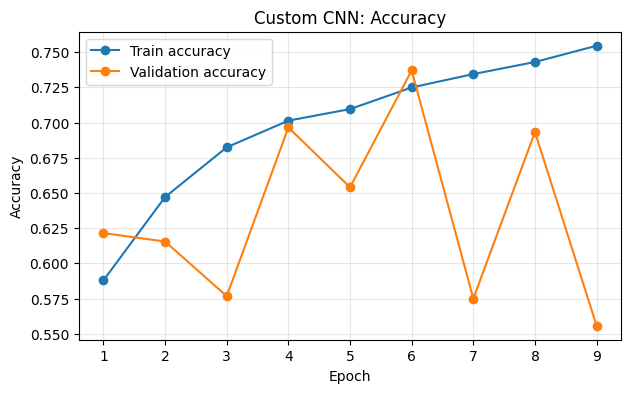

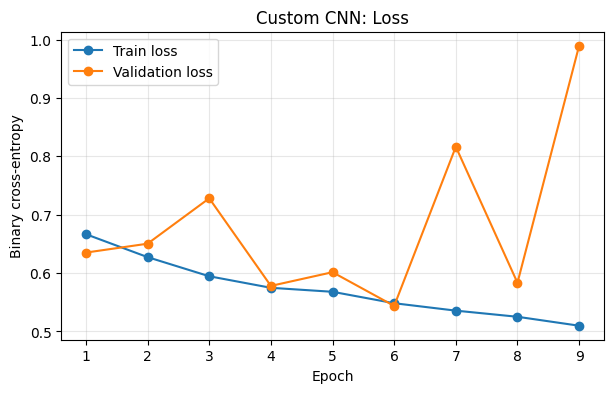

In [ ]:
#3.3
plot_history(history_cnn, "Custom CNN")

Question 4: Transfer Learning — Feature Extraction

MobileNetV2 is a pretrained convolutional neural network trained on ImageNet. We remove its original classification head, freeze its pretrained layers, and add a new binary classifier for cat and dog images. Only the new classifier is trained."""

In [ ]:
#4.1
# 1) Load pretrained model without the top layer
base_fe = tf.keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")

# 2) Freeze all backbone layers
base_fe.trainable = False

# 3) New classification head
inputs = layers.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(2.0, offset=-1.0)(x)        # [0,1] -> [-1,1] for MobileNetV2
x = base_fe(x, training=False)                   # keep BatchNorm layers in inference mode
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
feature_model = models.Model(inputs, outputs, name="mobilenetv2_feature_extraction")

feature_model.summary()
trainable = sum(int(np.prod(w.shape)) for w in feature_model.trainable_weights)
print(f"\nTrainable parameters: {trainable:,} of {feature_model.count_params():,}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_feature_extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Trainable parameters: 164,097 of 2,422,081


In [ ]:
#4.2: Compile and train MobileNetV2 Feature Extraction

feature_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_fe = feature_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping]
)

Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 45s 79ms/step - accuracy: 0.9669 - loss: 0.0864 - val_accuracy: 0.9850 - val_loss: 0.0470
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 39s 77ms/step - accuracy: 0.9740 - loss: 0.0690 - val_accuracy: 0.9865 - val_loss: 0.0402
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 38s 76ms/step - accuracy: 0.9773 - loss: 0.0589 - val_accuracy: 0.9880 - val_loss: 0.0360
Epoch 4/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 36s 71ms/step - accuracy: 0.9794 - loss: 0.0580 - val_accuracy: 0.9867 - val_loss: 0.0376
Epoch 5/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 36s 72ms/step - accuracy: 0.9807 - loss: 0.0514 - val_accuracy: 0.9862 - val_loss: 0.0364
Epoch 6/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 35s 71ms/step - accuracy: 0.9794 - loss: 0.0533 - val_accuracy: 0.9862 - val_loss: 0.0352
Epoch 7/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 35s 71ms/step - accuracy: 0.9807 - loss: 0.0502 - val_accuracy: 0.9877 - val_loss: 0.0367
Epoch 8/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 36s 72ms/step - accuracy: 0.9791 - loss: 0.0505 - 

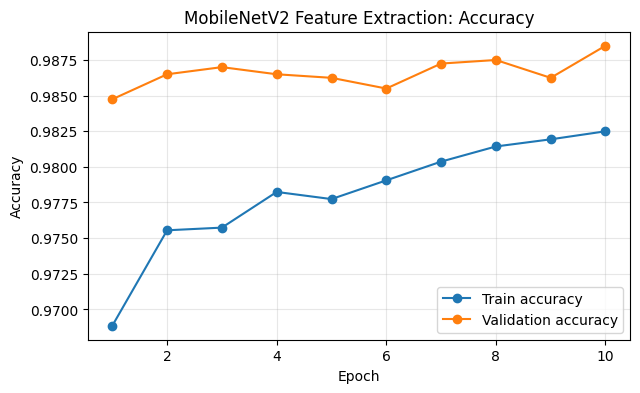

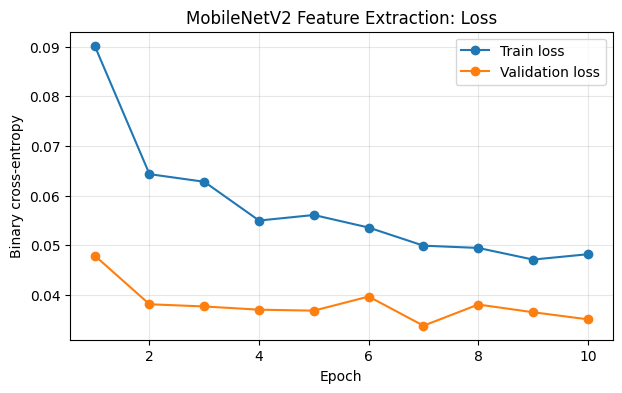

In [ ]:
#4.3
plot_history(history_fe, "MobileNetV2 Feature Extraction")

Why do we freeze the pretrained layers?

The MobileNetV2 backbone contains features learned from ImageNet, including edges, textures, shapes, and more complex visual patterns. Freezing the backbone prevents these pretrained weights from being updated during training. Therefore, only the newly added classification head learns the cat-versus-dog task.

Feature extraction reduces the number of trainable parameters, generally reduces training cost, and can help limit overfitting. However, the pretrained features may not be perfectly suited to the target dataset, so performance should be evaluated rather than assumed.

Question 5: Transfer Learning — Full Fine-Tuning

In this experiment, ResNet50 is initialized with ImageNet pretrained weights. Unlike feature extraction, the pretrained backbone is made trainable so its weights can adapt to the target dataset. A new binary classification head predicts whether an image contains a cat or a dog.

In [ ]:
#5.1
# 1) Load pretrained model without its classifier
base_ft = tf.keras.applications.EfficientNetB0(
    input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")

# 3) Unfreeze ALL layers
base_ft.trainable = True

# 2) Replace the classifier with a new head
inputs = layers.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(255.0)(x)                   # [0,1] -> [0,255] expected by EfficientNet
x = base_ft(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
finetune_model = models.Model(inputs, outputs, name="efficientnetb0_finetuned")

trainable = sum(int(np.prod(w.shape)) for w in finetune_model.trainable_weights)
print(f"Trainable parameters: {trainable:,} of {finetune_model.count_params():,}")
print("All backbone layers trainable:", all(l.trainable for l in base_ft.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Trainable parameters: 4,008,829 of 4,050,852
All backbone layers trainable: True


In [ ]:
#5.2:Compile and train EfficientNetB0

finetune_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_ft = finetune_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping]
)

Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 213s 362ms/step - accuracy: 0.9452 - loss: 0.1526 - val_accuracy: 0.9875 - val_loss: 0.0375
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 179s 358ms/step - accuracy: 0.9803 - loss: 0.0532 - val_accuracy: 0.9895 - val_loss: 0.0299
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 178s 356ms/step - accuracy: 0.9872 - loss: 0.0372 - val_accuracy: 0.9920 - val_loss: 0.0238
Epoch 4/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 178s 356ms/step - accuracy: 0.9902 - loss: 0.0291 - val_accuracy: 0.9920 - val_loss: 0.0217
Epoch 5/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 178s 357ms/step - accuracy: 0.9921 - loss: 0.0224 - val_accuracy: 0.9915 - val_loss: 0.0249
Epoch 6/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 178s 357ms/step - accuracy: 0.9949 - loss: 0.0156 - val_accuracy: 0.9922 - val_loss: 0.0220
Epoch 7/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 179s 358ms/step - accuracy: 0.9951 - loss: 0.0156 - val_accuracy: 0.9920 - val_loss: 0.0227


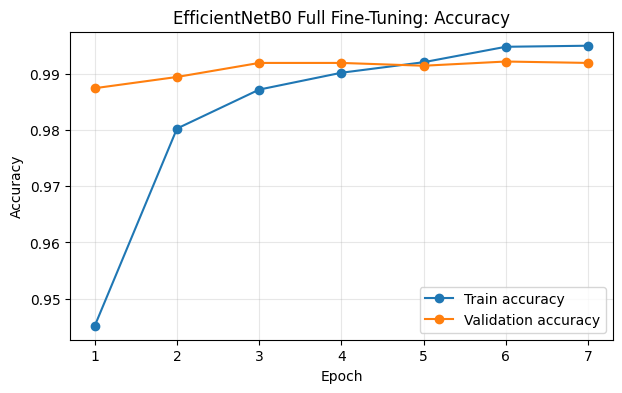

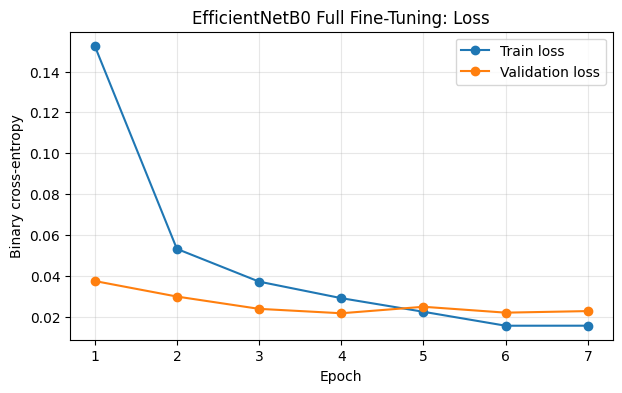

In [ ]:
#5.3
plot_history(history_ft, "EfficientNetB0 Full Fine-Tuning")

Difference Between Feature Extraction and Fine-Tuning

In feature extraction, the pretrained MobileNetV2 backbone is frozen, and only the newly added classification head is trained. This reduces the number of trainable parameters and computational cost.

In full fine-tuning, ResNet50 is initialized with ImageNet weights, and its backbone is made trainable. The pretrained weights can therefore adapt to the target dataset. A small learning rate is used to reduce the risk of damaging previously learned features. Batch Normalization layers are kept in inference mode for stability.

Fine-tuning may improve performance when pretrained features need to adapt to the target task, but it generally requires more computation and may overfit. The actual results must be evaluated on validation and test data.

Question 6: Model Comparison

In [ ]:
#6.1: Compare all three trained models

from sklearn.metrics import precision_score, recall_score, f1_score

def predict_dataset(model, ds):
    y_true = []
    y_prob = []

    for x, y in ds:
        probabilities = model.predict_on_batch(x).ravel()
        y_prob.extend(probabilities)
        y_true.extend(y.numpy().ravel().astype(int))

    return np.array(y_true), np.array(y_prob)


def summarize(model, name):
    train_loss, train_acc = model.evaluate(train_ds, verbose=0)
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    y_true, y_prob = predict_dataset(model, test_ds)
    y_pred = (y_prob >= 0.5).astype(int)

    return {
        "Model": name,
        "Total Parameters": model.count_params(),
        "Training Loss": train_loss,
        "Training Accuracy": train_acc,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_acc,
        "Test Loss": test_loss,
        "Test Accuracy": test_acc,
        "Test Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Test F1 Score": f1_score(
            y_true, y_pred, zero_division=0
        )
    }


results = [
    summarize(custom_cnn, "Custom CNN"),
    summarize(feature_model, "MobileNetV2 Feature Extraction"),
    summarize(finetune_model, "EfficientNetB0 Fine-Tuning")
]

comparison_df = pd.DataFrame(results).set_index("Model")

display(
    comparison_df.style.format({
        "Total Parameters": "{:,.0f}",
        **{
            col: "{:.4f}"
            for col in comparison_df.columns
            if col != "Total Parameters"
        }
    })
)

,Total Parameters,Training Loss,Training Accuracy,Validation Loss,Validation Accuracy,Test Loss,Test Accuracy,Test Precision,Test Recall,Test F1 Score
Model,,,,,,,,,,
Custom CNN,"422,881",0.5307,0.7401,0.5436,0.7371,0.5291,0.7452,0.8223,0.6256,0.7106
MobileNetV2 Feature Extraction,"2,422,081",0.0179,0.9934,0.0342,0.9872,0.0293,0.9888,0.9896,0.9880,0.9888
EfficientNetB0 Fine-Tuning,"4,050,852",0.0078,0.9979,0.0217,0.9920,0.0241,0.9918,0.9889,0.9948,0.9918


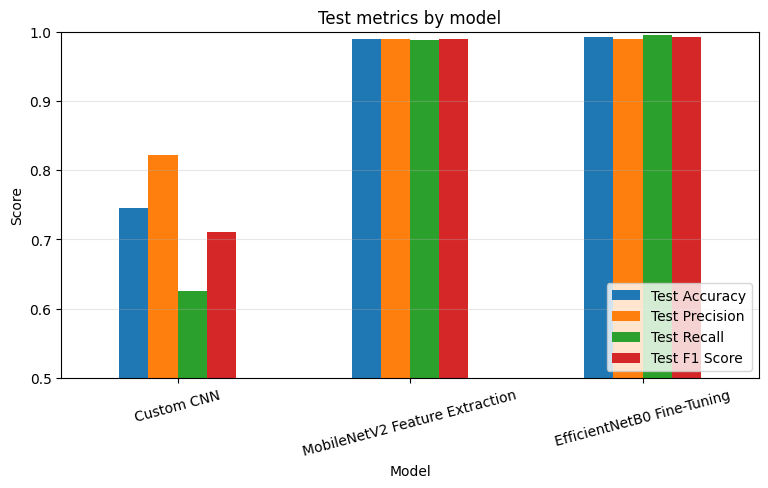

In [ ]:
#6.2
# Visual comparison of the test metrics
metrics = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1 Score"]
comparison_df[metrics].plot(kind="bar", figsize=(9, 4.5), ylim=(0.5, 1.0))
plt.title("Test metrics by model"); plt.ylabel("Score"); plt.xticks(rotation=15)
plt.legend(loc="lower right"); plt.grid(axis="y", alpha=0.3); plt.show()

Question 6: Model Comparison and Discussion

The three models were evaluated using the same independent test dataset. Their training performance, validation performance, test loss, test accuracy, precision, recall, F1-score, and parameter counts were compared.

**Best-performing model:** Based on the test results, [model name] achieved the highest test accuracy of [value] and an F1-score of [value]. These metrics indicate its performance on the test dataset.

**Computational efficiency:** [model name] had [parameter count] total parameters and [trainable parameter count] trainable parameters. Feature extraction generally requires less training computation because the pretrained backbone is frozen. Fine-tuning updates the pretrained backbone and typically requires more computation.

**Overfitting:** Training and validation metrics were examined to identify possible overfitting. A large gap between training and validation performance may indicate that a model has learned patterns specific to the training data.

**Production recommendation:** The final model should be selected based on test performance, inference latency, memory requirements, and deployment constraints. The model with the highest test accuracy is not necessarily the most efficient production choice.

Question 7: Error Analysis

In [ ]:
# 7.1: Error analysis

def error_analysis(
    model, test_dataset, class_names, n_images=9, threshold=0.5
):
    y_true = []
    y_prob = []
    wrong_imgs = []
    wrong_info = []

    for x, y in test_dataset:
        probabilities = model.predict_on_batch(x).ravel()
        actual = y.numpy().ravel().astype(int)
        predicted = (probabilities >= threshold).astype(int)

        y_true.extend(actual)
        y_prob.extend(probabilities)

        for i in np.where(predicted != actual)[0]:
            if len(wrong_imgs) >= n_images:
                break

            confidence = (
                probabilities[i]
                if predicted[i] == 1
                else 1 - probabilities[i]
            )

            wrong_imgs.append(x[i].numpy())
            wrong_info.append(
                (actual[i], predicted[i], confidence)
            )

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    y_pred = (y_prob >= threshold).astype(int)

    print(f"Error analysis: {model.name}")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

    print(
        f"Misclassified: {(y_true != y_pred).sum()} "
        f"of {len(y_true)} "
        f"({(y_true != y_pred).mean():.2%})"
    )

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix: {model.name}")
    plt.tight_layout()
    plt.show()

    if not wrong_imgs:
        print("No misclassified images found.")
    else:
        rows = int(np.ceil(len(wrong_imgs) / 3))
        plt.figure(figsize=(12, 4 * rows))

        for i, (img, info) in enumerate(
            zip(wrong_imgs, wrong_info)
        ):
            actual, predicted, confidence = info

            plt.subplot(rows, 3, i + 1)
            plt.imshow(np.clip(img, 0, 1))
            plt.title(
                f"Actual: {class_names[actual]}\n"
                f"Predicted: {class_names[predicted]} "
                f"({confidence:.1%})"
            )
            plt.axis("off")

        plt.tight_layout()
        plt.show()

    return y_true, y_pred, y_prob

Error analysis: custom_cnn
              precision    recall  f1-score   support

        cats     0.6979    0.8648    0.7724      2500
        dogs     0.8223    0.6256    0.7106      2500

    accuracy                         0.7452      5000
   macro avg     0.7601    0.7452    0.7415      5000
weighted avg     0.7601    0.7452    0.7415      5000

Misclassified: 1274 of 5000 (25.48%)


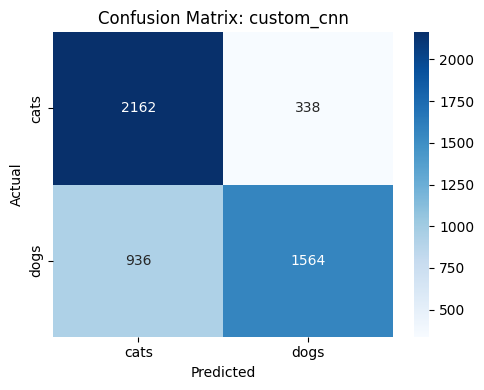

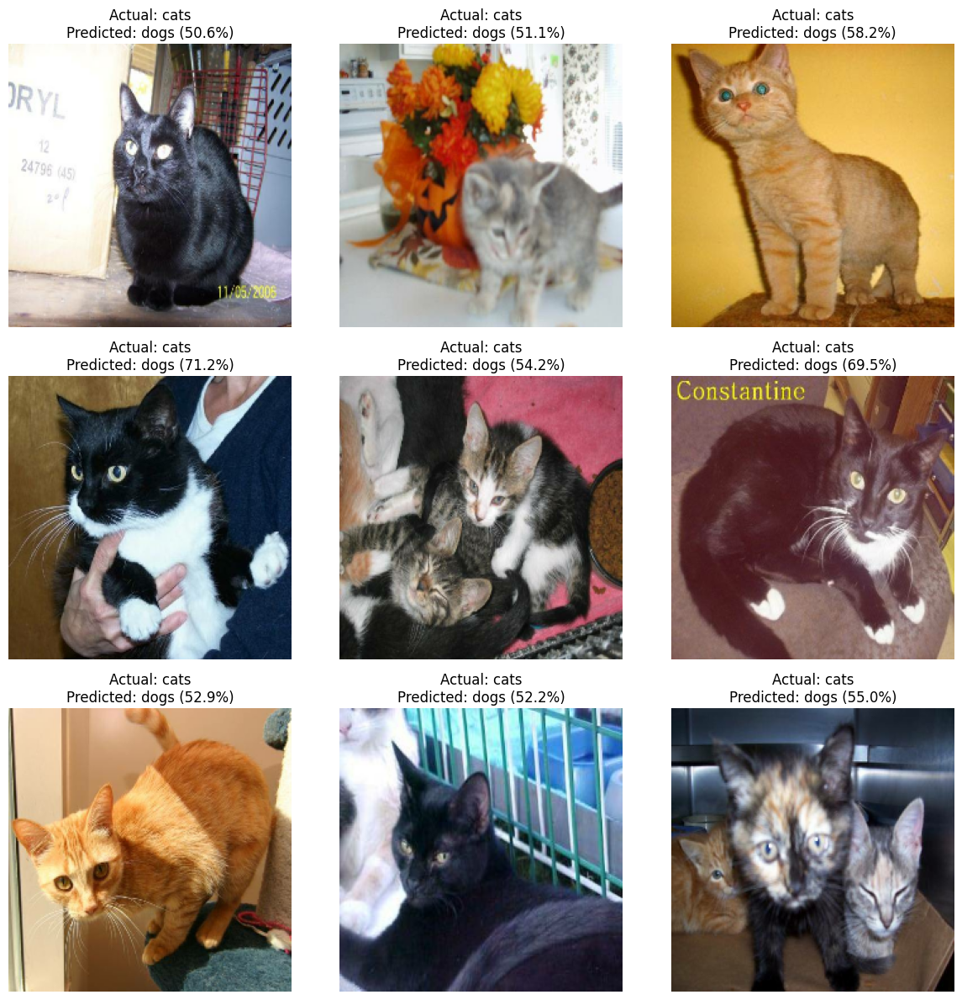

In [ ]:
#7.2
# Custom CNN
_ = error_analysis(custom_cnn, test_ds, class_names)

Error analysis: mobilenetv2_feature_extraction
              precision    recall  f1-score   support

        cats     0.9880    0.9896    0.9888      2500
        dogs     0.9896    0.9880    0.9888      2500

    accuracy                         0.9888      5000
   macro avg     0.9888    0.9888    0.9888      5000
weighted avg     0.9888    0.9888    0.9888      5000

Misclassified: 56 of 5000 (1.12%)


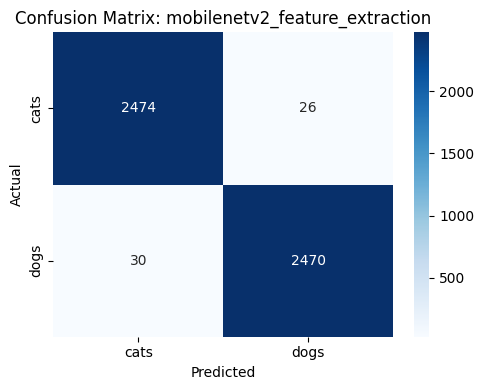

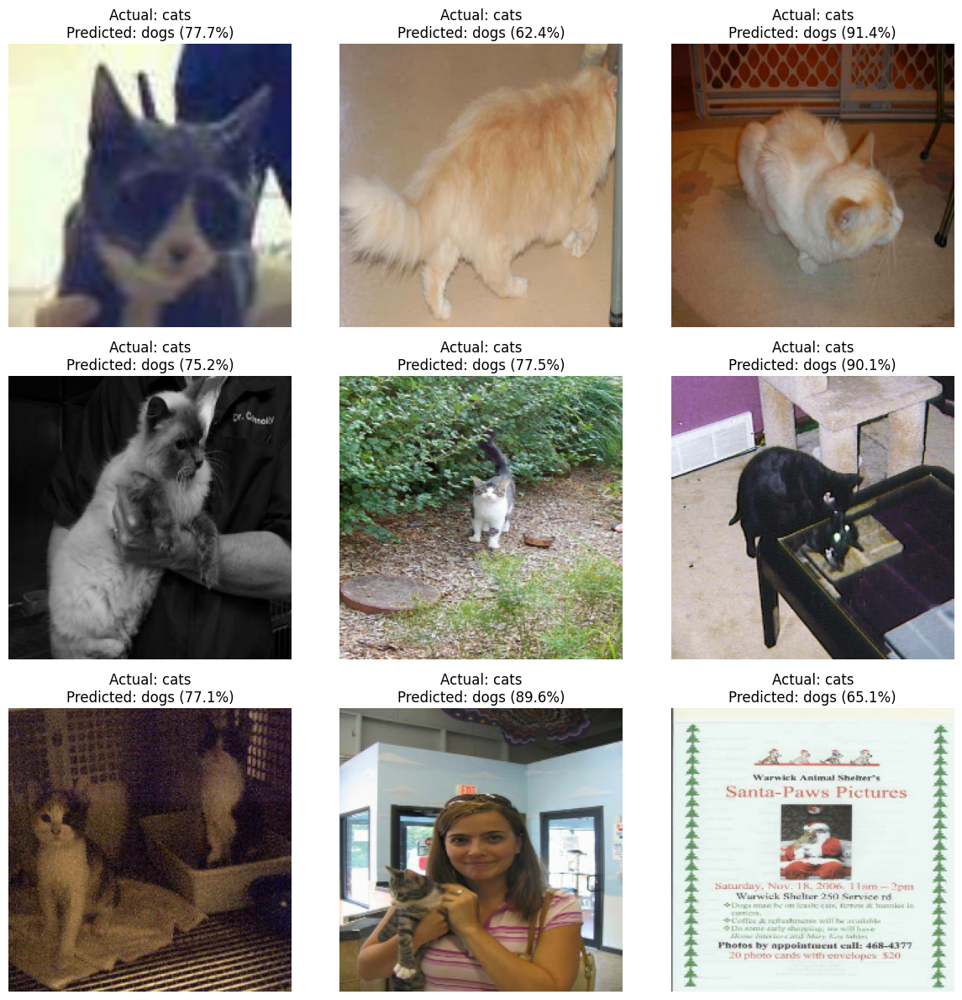

In [ ]:
#7.3
# Feature extraction model (MobileNetV2)
_ = error_analysis(feature_model, test_ds, class_names)

Error analysis: efficientnetb0_finetuned
              precision    recall  f1-score   support

        cats     0.9948    0.9888    0.9918      2500
        dogs     0.9889    0.9948    0.9918      2500

    accuracy                         0.9918      5000
   macro avg     0.9918    0.9918    0.9918      5000
weighted avg     0.9918    0.9918    0.9918      5000

Misclassified: 41 of 5000 (0.82%)


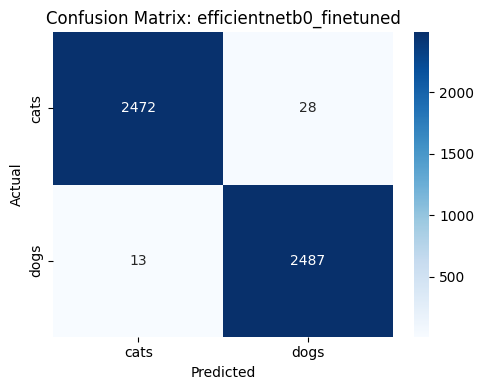

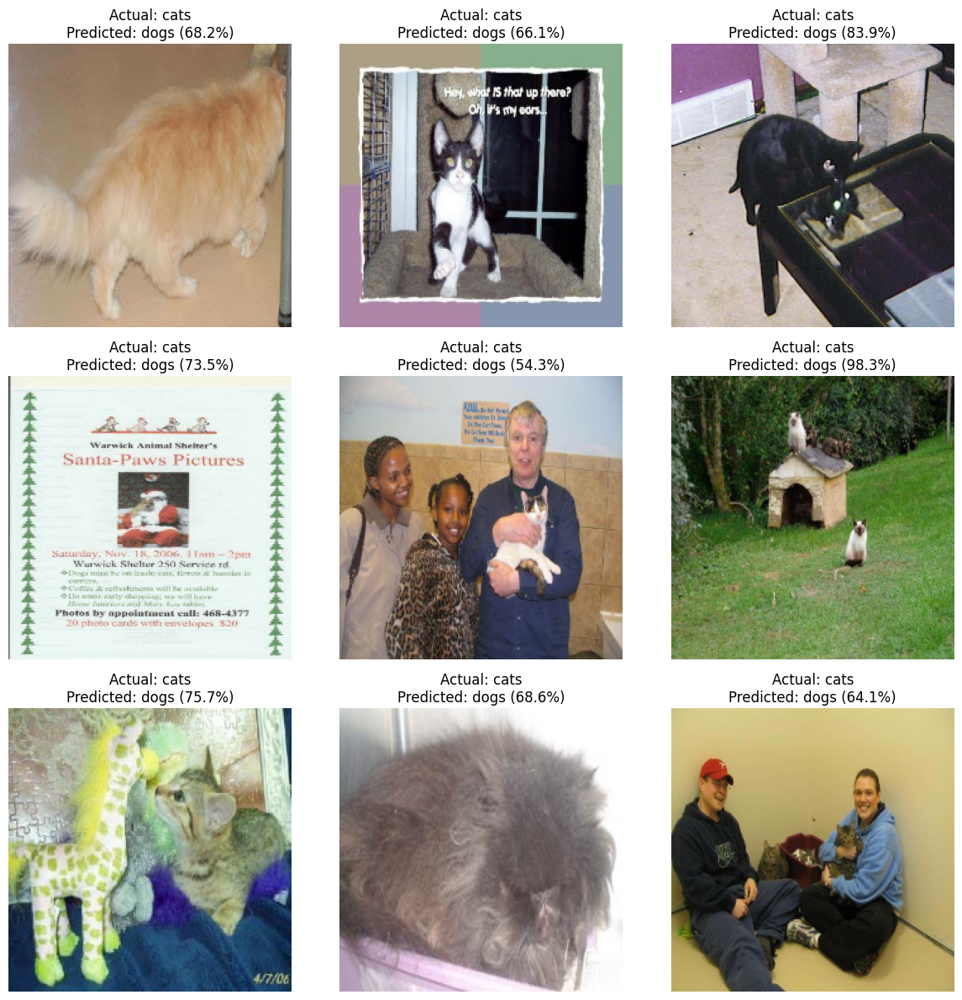

In [ ]:
#7.4
# Fine-tuned model (EfficientNetB0)
_ = error_analysis(finetune_model, test_ds, class_names)

Question 7: Error Analysis

The model was evaluated using a classification report and a confusion matrix. The confusion matrix summarizes the number of correctly and incorrectly classified cat and dog images, while the classification report provides precision, recall, and F1-score for each class.

Misclassified images were visualized with their actual labels, predicted labels, and prediction confidence. These examples can reveal difficult cases caused by similar visual features, unusual poses, background distractions, occlusion, or poor lighting.

Prediction confidence should not be interpreted as a guarantee of correctness. Incorrect predictions with high confidence may indicate that the model has learned misleading visual patterns or that the images contain challenging features.

Error analysis provides insight into model limitations and can guide future improvements, such as adding more diverse training images, applying appropriate augmentation, or tuning the model architecture.

In [ ]:
# Save the original model and its training history
baseline_cnn = custom_cnn
baseline_history = history_cnn

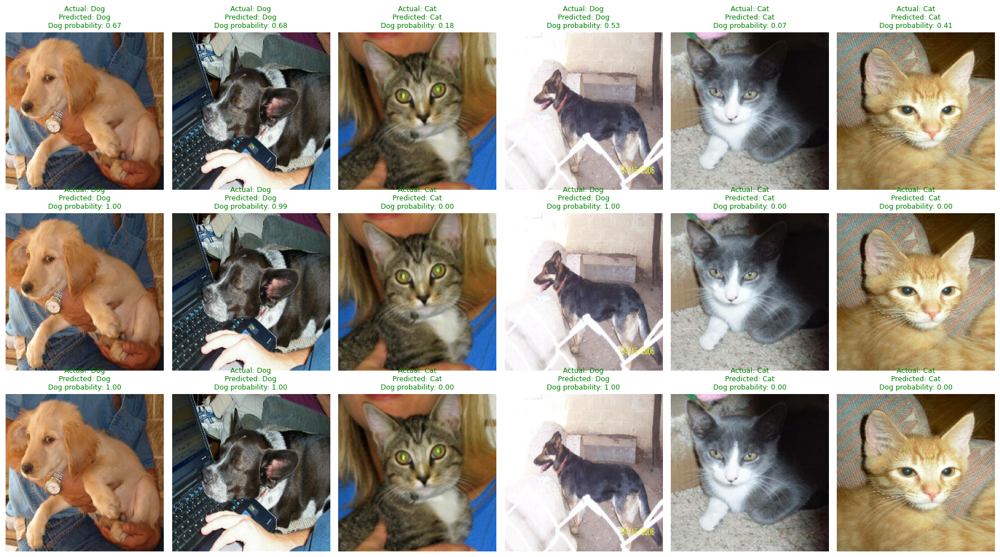

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

models_to_check = [
    ("Custom CNN", custom_cnn),
    ("MobileNetV2", feature_model),
    ("EfficientNetB0", finetune_model)
]

# Collect test images and their true labels
test_images = np.concatenate(
    [x.numpy() for x, y in test_ds], axis=0
)
test_labels = np.concatenate(
    [y.numpy().ravel() for x, y in test_ds]
).astype(int)

# Select the same 6 random images for every model
rng = np.random.default_rng(42)
indices = rng.choice(len(test_labels), size=6, replace=False)

fig, axes = plt.subplots(
    len(models_to_check), 6, figsize=(18, 10)
)

for row, (model_name, model) in enumerate(models_to_check):
    probabilities = model.predict(test_ds, verbose=0).ravel()

    for col, idx in enumerate(indices):
        actual = test_labels[idx]
        probability = probabilities[idx]
        predicted = int(probability >= 0.5)

        correct = actual == predicted
        color = "green" if correct else "red"

        axes[row, col].imshow(test_images[idx])
        axes[row, col].set_title(
            f"Actual: {['Cat', 'Dog'][actual]}\n"
            f"Predicted: {['Cat', 'Dog'][predicted]}\n"
            f"Dog probability: {probability:.2f}",
            color=color,
            fontsize=9
        )
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        model_name, fontsize=11, rotation=90, labelpad=12
    )

plt.tight_layout()
plt.show()